In [201]:
import torch 
import torch.nn as nn
import torchvision 
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

import torch.backends
import torch.backends.mps

import torch.utils
import torch.utils.data

from torch.optim.lr_scheduler import StepLR
from torch.utils.tensorboard import SummaryWriter
import copy


In [2]:
# device config
if torch.backends.mps.is_available(): 
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else: 
    device = torch.device("cpu")

device

device(type='mps')

In [190]:
mean = torch.tensor([0.485, 0.456, 0.406])
std = torch.tensor([0.229, 0.224, 0.225])


simple_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

complex_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

In [202]:

# train_dataset = torchvision.datasets.CIFAR10(root="data", train=True, transform=compose_transform, download=True)
# augmented_train = torchvision.datasets.CIFAR10(root="data", train=True, transform=complex_transform, download=True)

# # test and val are const
# test_dataset = torchvision.datasets.CIFAR10(root="data", train=False, transform=compose_transform, download=True)
# test_dataset, val_dataset = torch.utils.data.random_split(test_dataset, [5000, 5000])

### loading from local 
full_dataset_simple = torchvision.datasets.ImageFolder(root="./data/cifar10")

# 0.8, 0.1, 0.1 split
val_and_test_size = int(0.1 * len(full_dataset_simple))
train_size = len(full_dataset_simple) - 2 * val_and_test_size

train_dataset, test_dataset, val_dataset = torch.utils.data.random_split(full_dataset_simple, [train_size, val_and_test_size, val_and_test_size])
augmented_train = copy.deepcopy(train_dataset)

# add transforms 
train_dataset.dataset.transform = simple_transform
augmented_train.dataset.transform = complex_transform

# check transforms 
print("Simple transform: ", train_dataset.dataset.transform)
print("Complex transform: ", augmented_train.dataset.transform)

total = len(train_dataset) + len(test_dataset) + len(val_dataset)

print("Len of train_dataset: ", len(train_dataset))
print("Len of test_dataset: ", len(test_dataset))
print("Len of val_dataset: ", len(val_dataset))

print(f"Percentage splits of train, test, val: {len(train_dataset)/total*100:.2f}%, {len(test_dataset)/total*100:.2f}%, {len(val_dataset)/total*100:.2f}%")

Simple transform:  Compose(
    ToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)
Complex transform:  Compose(
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.9, 1.1), hue=(-0.1, 0.1))
    ToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)
Len of train_dataset:  40000
Len of test_dataset:  5000
Len of val_dataset:  5000
Percentage splits of train, test, val: 80.00%, 10.00%, 10.00%


In [5]:
batch_size = 64

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
augmented_loader = torch.utils.data.DataLoader(dataset=augmented_train, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)
val_loader = torch.utils.data.DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)

In [6]:
examples = iter(train_loader) 

samples, labels = examples._next_data()

# samples shape: [batch_size, channels, height, width]
# labels: 0 - 9
samples.shape, labels.shape

(torch.Size([64, 3, 32, 32]), torch.Size([64]))

In [7]:
# 3 arrays (each array contains color values of single channel)
samples[0]

tensor([[[ 1.7180,  1.6324,  1.6324,  ...,  1.7180,  1.7352,  1.8208],
         [ 1.6667,  1.5982,  1.6153,  ...,  1.6838,  1.6838,  1.7865],
         [ 1.6838,  1.5982,  1.5982,  ...,  1.7009,  1.7180,  1.8208],
         ...,
         [ 1.1187,  0.8276,  1.4098,  ..., -0.9705, -1.4329, -1.5357],
         [ 1.2728,  0.8104,  1.2385,  ..., -1.4329, -1.5185, -1.3644],
         [ 1.4783,  0.8104,  1.1358,  ..., -1.4329, -1.2445, -0.9363]],

        [[ 1.9734,  1.8859,  1.8859,  ...,  1.9734,  1.9909,  2.0784],
         [ 1.9209,  1.8508,  1.8683,  ...,  1.9384,  1.9384,  2.0434],
         [ 1.9384,  1.8508,  1.8508,  ...,  1.9559,  1.9734,  2.0609],
         ...,
         [-0.6352, -0.4426, -0.5826,  ..., -1.1604, -1.3354, -1.1954],
         [-0.7752, -0.6001, -0.6352,  ..., -1.2479, -1.2304, -1.0203],
         [-0.8627, -0.7227, -0.6001,  ..., -1.1078, -1.0028, -0.8277]],

        [[ 2.2566,  2.1694,  2.1694,  ...,  2.2566,  2.2740,  2.3611],
         [ 2.2043,  2.1346,  2.1520,  ...,  2

In [8]:
# single color channel, 32 rows, each row has 32 values (forming columns)
samples[0][0]

tensor([[ 1.7180,  1.6324,  1.6324,  ...,  1.7180,  1.7352,  1.8208],
        [ 1.6667,  1.5982,  1.6153,  ...,  1.6838,  1.6838,  1.7865],
        [ 1.6838,  1.5982,  1.5982,  ...,  1.7009,  1.7180,  1.8208],
        ...,
        [ 1.1187,  0.8276,  1.4098,  ..., -0.9705, -1.4329, -1.5357],
        [ 1.2728,  0.8104,  1.2385,  ..., -1.4329, -1.5185, -1.3644],
        [ 1.4783,  0.8104,  1.1358,  ..., -1.4329, -1.2445, -0.9363]])

In [9]:
# single row, auto normalized (0-1) form oringinal (0-255) by ToTensor() transform
samples[0][0][0]

tensor([1.7180, 1.6324, 1.6324, 1.6324, 1.6324, 1.6324, 1.6153, 1.5982, 1.6153,
        1.6324, 1.6324, 1.6324, 1.6324, 1.6667, 1.6495, 1.7009, 1.6495, 0.7762,
        0.6563, 0.8961, 0.4508, 0.1426, 0.8276, 1.6667, 1.6838, 1.7009, 1.7180,
        1.7180, 1.7180, 1.7180, 1.7352, 1.8208])

In [10]:
# single value correspoding to class label
labels[0]

tensor(8)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


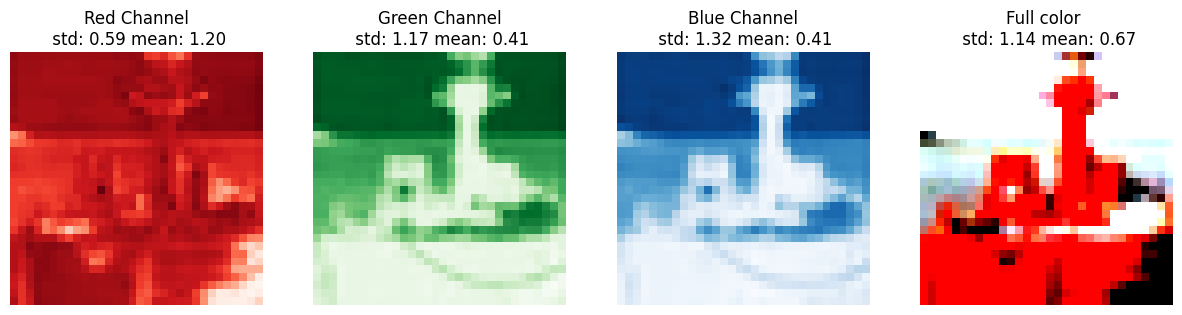

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


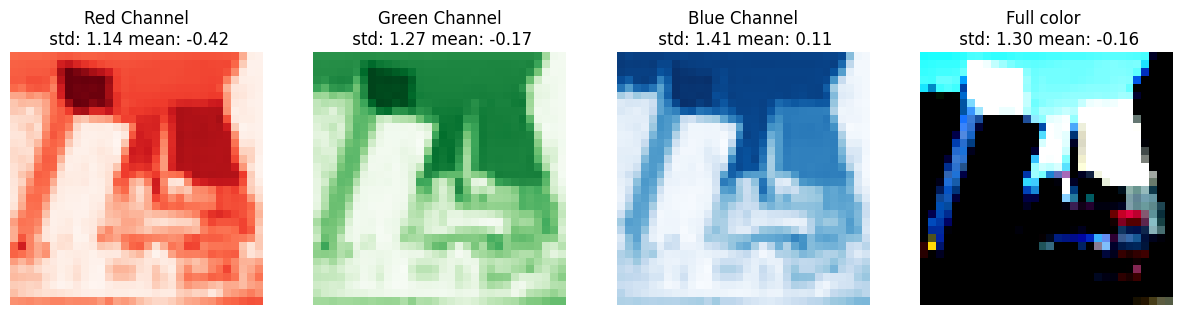

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


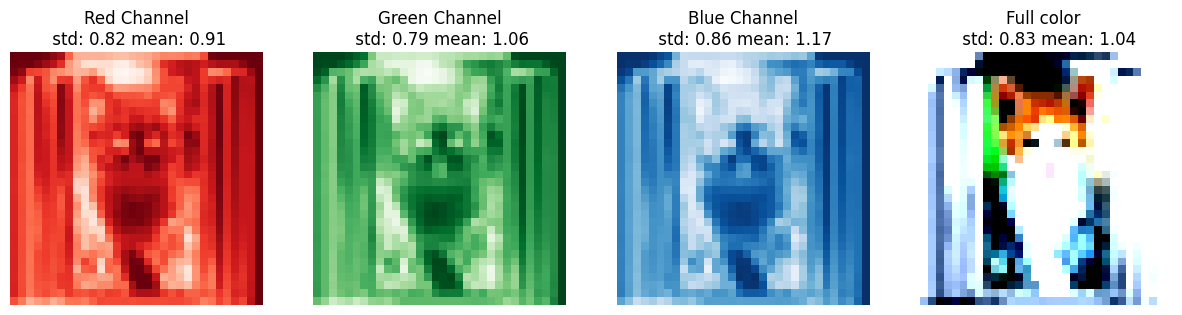

In [11]:
# color of the images
for j in range(3): 
    image = samples[j]

    red_channel = image[0, :, :]
    green_channel = image[1, :, :]
    blue_channel = image[2, :, :]

    fig, axs = plt.subplots(1, 4, figsize=(15, 5))

    # Plotting Red Channel
    std = red_channel.std().item()
    mean = red_channel.mean().item()

    axs[0].imshow(red_channel, cmap='Reds')
    axs[0].set_title('Red Channel\n std: {:.2f} mean: {:.2f}'.format(std, mean))
    axs[0].axis('off')  # Hide axes

    # Plotting Green Channel
    std = green_channel.std().item()
    mean = green_channel.mean().item()

    axs[1].imshow(green_channel, cmap='Greens')
    axs[1].set_title('Green Channel\n std: {:.2f} mean: {:.2f}'.format(std, mean))
    axs[1].axis('off')  # Hide axes

    # Plotting Blue Channel
    std = blue_channel.std().item()
    mean = blue_channel.mean().item()

    axs[2].imshow(blue_channel, cmap='Blues')
    axs[2].set_title('Blue Channel\n std: {:.2f} mean: {:.2f}'.format(std, mean))
    axs[2].axis('off')  # Hide axes
    
    # Plotting in color
    std = image.std().item()
    mean = image.mean().item()

    image = image.permute(1, 2, 0)

    axs[3].imshow(image)
    axs[3].set_title('Full color \n std: {:.2f} mean: {:.2f}'.format(std, mean))
    axs[3].axis('off')  # Hide axes

    # Displaying the plots
    plt.show()

In [12]:
# channels is the 1st dimension, reducing all other dimensions
# output: len(channels)
# the batch is normalized well (better than each image)
torch.mean(samples, dim=(0, 2, 3)), torch.std(samples, dim=(0, 2, 3))

(tensor([0.0741, 0.0968, 0.1460]), tensor([1.0904, 1.0916, 1.1745]))

In [14]:
# calculate mean and std of each channel
mean = torch.tensor(data=(0.0, 0.0, 0.0))
std = torch.tensor(data=(0.0, 0.0, 0.0))

for images, _ in train_loader:
    mean += torch.mean(images, dim=(0, 2, 3))
    std += torch.std(images, dim=(0, 2, 3))

mean = mean / len(train_loader)
std = std / len(train_loader)

# after transform here will be 0 mean and 1 std
mean, std

(tensor([0.0278, 0.1167, 0.1800]), tensor([1.0759, 1.0842, 1.1589]))

In [26]:
# remove tensorboard logs if it exists
!rm -rf runs

tf_iter = 0

In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiFCPatchProcessor(nn.Module):
    def __init__(self, input_channels, patch_size, num_layers, output_per_layer, num_classes, image_height, image_width, hidden_size):
        super(MultiFCPatchProcessor, self).__init__()
        self.input_channels = input_channels
        self.patch_size = patch_size
        self.num_layers = num_layers
        self.output_per_layer = output_per_layer
        self.num_classes = num_classes

        output_height = image_height - self.patch_size + 1
        output_width = image_width - self.patch_size + 1

        # Create multiple fully connected layers
        self.fc_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(input_channels * patch_size * patch_size, output_per_layer), 
                nn.LeakyReLU(negative_slope=0.01), 
                nn.Dropout(0.3)
                ) for _ in range(num_layers)
        ])

        self.final_fc = nn.Sequential(
            nn.Linear(output_height * output_width * num_layers, hidden_size), 
            nn.LeakyReLU(negative_slope=0.01),
            nn.Dropout(0.3),

            nn.Linear(hidden_size, num_classes), 
            nn.LeakyReLU(negative_slope=0.01)
        )

    def forward(self, x):
        # Calculate dimensions based on the patch size (assuming stride=1 and no padding for simplicity)
        output_height = x.shape[2] - self.patch_size + 1
        output_width = x.shape[3] - self.patch_size + 1

        # Extract patches
        patches = x.unfold(2, self.patch_size, 1).unfold(3, self.patch_size, 1)
        patches = patches.contiguous().view(x.size(0), -1, self.input_channels * self.patch_size * self.patch_size)

        # Process each patch through each FC layer
        outputs = []
        for fc in self.fc_layers:
            # Apply the fully connected layer to each patch
            out = fc(patches)
            # Reshape to match the spatial layout
            out = out.view(x.size(0), output_height, output_width, self.output_per_layer)

            outputs.append(out)

        # Combine outputs across all layers
        # Concatenate along the last dimension to combine features from different FC layers
        combined_output = torch.cat(outputs, dim=3) 

        # Flatten the output
        combined_output = combined_output.view(x.size(0), -1)

        # Pass through final fully connected layer
        final_output = self.final_fc(combined_output)

        return final_output

In [23]:
input_channels = samples.shape[1]
patch_size = 5
num_layers = 20
outputs_per_layer = 1
num_classes = 10
hidden_size = 256
image_height = samples.shape[2]
image_width = samples.shape[3]

model = MultiFCPatchProcessor(input_channels=input_channels, patch_size=patch_size, num_layers=num_layers, output_per_layer=outputs_per_layer, num_classes=num_classes, image_height = image_height, image_width=image_width, hidden_size = hidden_size)
output_feature_map = model(samples)

output_feature_map.shape

torch.Size([64, 10])

In [1]:
# ### load model from gpu cloud
# model.load_state_dict(torch.load('./model_state_dict.pth', map_location=device))
# model.to(device)

In [24]:
import os

### new model
model = MultiFCPatchProcessor(input_channels=input_channels, patch_size=patch_size, num_layers=num_layers, output_per_layer=outputs_per_layer, num_classes=num_classes, image_height = image_height, image_width=image_width, hidden_size=hidden_size)
model = model.to(device)

# check model param data
torch.save(model.state_dict(), './model_state_dict_intermediate.pth')

# check model params
n_params = sum(p.numel() for p in model.parameters())
print("Number of params (< 5M) ", n_params / 1e6) # < 5_000_000

size = os.path.getsize('./model_state_dict_intermediate.pth') # < 20MB
print("MB size: (< 20 MB) ", size / 1e6)

Number of params (< 5M)  4.018426
MB size: (< 20 MB)  16.091378


In [27]:
# start tensorboard
tf_iter += 1
writer = SummaryWriter(f'runs/cifar_fc_{tf_iter}')

augmented_epochs = 30
normal_epochs = 15

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = StepLR(optimizer, step_size=1, gamma=0.99)

training_step = 0 
epoch_step = 0 

# using different dataloaders (augmented and normal)
def train_model(dataloader, epochs):
    global training_step 
    global epoch_step 
    
    for epoch in range(epochs): 
        training_acc = 0 

        for i, (images, labels) in enumerate(dataloader): 
            images = images.to(device) 
            labels = labels.to(device) 

            outputs = model(images) 
            loss = criterion(outputs, labels) 

            training_acc += (outputs.argmax(dim=1) == labels).sum().item()

            optimizer.zero_grad()
            loss.backward()

            optimizer.step()

            # current training step, tracking for tensorboard
            training_step += 1
            writer.add_scalar('training loss', loss.item(), training_step)

            # if i % 100 == 0: 
            #     print(f"Epoch {epoch+1}/{epochs}, Step {i}/{len(train_loader)}, Loss: {loss.item():.4f}")

        epoch_step += 1

        training_acc /= len(train_dataset)
        writer.add_scalar('training accuracy', training_acc, epoch_step)
        
        # drop learning rate
        scheduler.step()
        writer.add_scalar('learning rate', scheduler.get_last_lr()[0], epoch_step)

        if epoch % 5 == 0: 
            torch.save(model.state_dict(), './model_state_dict_intermediate.pth')

        # validation 
        with torch.no_grad(): 
            n_correct = 0
            n_samples = 0

            for images, labels in val_loader: 
                images = images.to(device)
                labels = labels.to(device)
                
                outputs = model(images)

                _, predicted = torch.max(outputs, 1)
                n_samples += labels.size(0)
                n_correct += (predicted == labels).sum().item()

            acc = 100.0 * n_correct / n_samples
            writer.add_scalar('validation accuracy', acc, epoch_step)
            print(f"Epoch {epoch+1}/{epochs}, Val Loss: {loss.item():.4f}, Accuracy: {acc:.2f}")

train_model(augmented_loader, augmented_epochs)

# increase lr decay for fitting
scheduler = StepLR(optimizer, step_size=1, gamma=0.95)

train_model(train_loader, normal_epochs)


Epoch 1/30, Val Loss: 1.8353, Accuracy: 33.22
Epoch 2/30, Val Loss: 1.6680, Accuracy: 39.26


KeyboardInterrupt: 

In [ ]:
# save after training
torch.save(model.state_dict(), './model_state_dict.pth')